In [1]:
import kagglehub

path = kagglehub.dataset_download("wordsforthewise/lending-club")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'lending-club' dataset.
Path to dataset files: /kaggle/input/lending-club


In [2]:
import os

print(os.listdir(path))

['rejected_2007_to_2018Q4.csv.gz', 'accepted_2007_to_2018Q4.csv.gz', 'accepted_2007_to_2018q4.csv', 'rejected_2007_to_2018q4.csv']


In [3]:
import os

for root, dirs, files in os.walk(path):
    print("FOLDER:", root)
    print("FILES:", files)

FOLDER: /kaggle/input/lending-club
FILES: ['rejected_2007_to_2018Q4.csv.gz', 'accepted_2007_to_2018Q4.csv.gz']
FOLDER: /kaggle/input/lending-club/accepted_2007_to_2018q4.csv
FILES: ['accepted_2007_to_2018Q4.csv']
FOLDER: /kaggle/input/lending-club/rejected_2007_to_2018q4.csv
FILES: ['rejected_2007_to_2018Q4.csv']


In [4]:
import pandas as pd

file_path = "/kaggle/input/lending-club/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2260701
Columns: 151


In [5]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df["loan_status"].value_counts(dropna=False)

,count
loan_status,
Fully Paid,1076751
Current,878317
Charged Off,268559
Late (31-120 days),21467
In Grace Period,8436
Late (16-30 days),4349
Does not meet the credit policy. Status:Fully Paid,1988
Does not meet the credit policy. Status:Charged Off,761
Default,40


In [7]:
model_df = df[df["loan_status"].isin([
    "Fully Paid",
    "Charged Off",
    "Default"
])].copy()

# Default = 1, Non-default = 0
model_df["default"] = (
    model_df["loan_status"]
    .isin(["Charged Off", "Default"])
    .astype(int)
)

print(model_df["default"].value_counts())

default
0    1076751
1     268599
Name: count, dtype: int64


In [8]:
print(model_df.columns.tolist())

['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq',

In [9]:
for i, col in enumerate(model_df.columns):
    print(i, col)

0 id
1 member_id
2 loan_amnt
3 funded_amnt
4 funded_amnt_inv
5 term
6 int_rate
7 installment
8 grade
9 sub_grade
10 emp_title
11 emp_length
12 home_ownership
13 annual_inc
14 verification_status
15 issue_d
16 loan_status
17 pymnt_plan
18 url
19 desc
20 purpose
21 title
22 zip_code
23 addr_state
24 dti
25 delinq_2yrs
26 earliest_cr_line
27 fico_range_low
28 fico_range_high
29 inq_last_6mths
30 mths_since_last_delinq
31 mths_since_last_record
32 open_acc
33 pub_rec
34 revol_bal
35 revol_util
36 total_acc
37 initial_list_status
38 out_prncp
39 out_prncp_inv
40 total_pymnt
41 total_pymnt_inv
42 total_rec_prncp
43 total_rec_int
44 total_rec_late_fee
45 recoveries
46 collection_recovery_fee
47 last_pymnt_d
48 last_pymnt_amnt
49 next_pymnt_d
50 last_credit_pull_d
51 last_fico_range_high
52 last_fico_range_low
53 collections_12_mths_ex_med
54 mths_since_last_major_derog
55 policy_code
56 application_type
57 annual_inc_joint
58 dti_joint
59 verification_status_joint
60 acc_now_delinq
61 tot_col

In [10]:
model_df[
    [
        "loan_amnt",
        "annual_inc",
        "int_rate",
        "dti",
        "fico_range_low",
        "fico_range_high",
        "delinq_2yrs",
        "inq_last_6mths",
        "default"
    ]
].describe()

,loan_amnt,annual_inc,int_rate,dti,fico_range_low,fico_range_high,delinq_2yrs,inq_last_6mths,default
count,1.345350e+06,1.345350e+06,1.345350e+06,1.344976e+06,1.345350e+06,1.345350e+06,1.345350e+06,1.345349e+06,1.345350e+06
mean,1.441997e+04,7.624757e+04,1.323971e+01,1.828264e+01,6.961853e+02,7.001854e+02,3.177917e-01,6.550761e-01,1.996499e-01
std,8.717098e+03,6.992485e+04,4.768782e+00,1.116041e+01,3.185280e+01,3.185345e+01,8.779831e-01,9.377690e-01,3.997373e-01
min,5.000000e+02,0.000000e+00,5.310000e+00,-1.000000e+00,6.250000e+02,6.290000e+02,0.000000e+00,0.000000e+00,0.000000e+00
25%,8.000000e+03,4.578000e+04,9.750000e+00,1.179000e+01,6.700000e+02,6.740000e+02,0.000000e+00,0.000000e+00,0.000000e+00
50%,1.200000e+04,6.500000e+04,1.274000e+01,1.761000e+01,6.900000e+02,6.940000e+02,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.000000e+04,9.000000e+04,1.599000e+01,2.406000e+01,7.100000e+02,7.140000e+02,0.000000e+00,1.000000e+00,0.000000e+00
max,4.000000e+04,1.099920e+07,3.099000e+01,9.990000e+02,8.450000e+02,8.500000e+02,3.900000e+01,8.000000e+00,1.000000e+00


In [11]:
comparison = model_df.groupby("default")[
    [
        "loan_amnt",
        "annual_inc",
        "int_rate",
        "dti",
        "fico_range_low",
        "fico_range_high",
        "delinq_2yrs",
        "inq_last_6mths"
    ]
].mean()

comparison


,loan_amnt,annual_inc,int_rate,dti,fico_range_low,fico_range_high,delinq_2yrs,inq_last_6mths
default,,,,,,,,
0,14134.369808,77705.945505,12.623288,17.811629,698.263902,702.264062,0.309296,0.624426
1,15564.874590,70401.305617,15.710784,20.170763,687.852431,691.852483,0.351848,0.777944


In [12]:
check_cols = [
    "loan_amnt",
    "annual_inc",
    "int_rate",
    "dti",
    "fico_range_low",
    "fico_range_high",
    "delinq_2yrs",
    "inq_last_6mths"
]

missing = model_df[check_cols].isna().sum().sort_values(ascending=False)

missing_pct = (
    missing / len(model_df) * 100
).round(2)

pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
})

,missing_count,missing_pct
dti,374,0.03
inq_last_6mths,1,0.00
annual_inc,0,0.00
loan_amnt,0,0.00
int_rate,0,0.00
fico_range_low,0,0.00
fico_range_high,0,0.00
delinq_2yrs,0,0.00


In [13]:
print("annual_inc <= 0:", (model_df["annual_inc"] <= 0).sum())
print("dti < 0:", (model_df["dti"] < 0).sum())
print("dti > 100:", (model_df["dti"] > 100).sum())

annual_inc <= 0: 361
dti < 0: 2
dti > 100: 533


In [14]:
print("Annual income quantiles:")
print(
    model_df["annual_inc"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
    )
)

print("\nDTI quantiles:")
print(
    model_df["dti"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
    )
)

Annual income quantiles:
0.00           0.0
0.01       18000.0
0.05       28000.0
0.25       45780.0
0.50       65000.0
0.75       90000.0
0.95      155000.0
0.99      250000.0
1.00    10999200.0
Name: annual_inc, dtype: float64

DTI quantiles:
0.00     -1.00
0.01      1.78
0.05      4.98
0.25     11.79
0.50     17.61
0.75     24.06
0.95     32.99
0.99     38.47
1.00    999.00
Name: dti, dtype: float64


In [15]:
dti_suspicious = model_df[
    (model_df["dti"] < 0) |
    (model_df["dti"] > 100)
]

dti_suspicious.groupby("default").size()

,0
default,
0,392
1,143


In [16]:
dti_suspicious[
    ["dti", "annual_inc", "loan_amnt", "int_rate", "default"]
].head(20)

,dti,annual_inc,loan_amnt,int_rate,default
8721,999.00,1770.00,6550.0,17.86,0
10548,137.40,20000.00,15000.0,16.55,0
22841,100.09,27000.00,20000.0,18.20,0
55648,120.66,8700.00,15000.0,15.41,0
66461,380.53,5000.00,19000.0,16.99,0
73833,672.52,1200.00,12000.0,19.99,0
77957,125.25,9745.00,12000.0,17.86,0
97333,104.00,12000.00,5000.0,13.99,0
421631,112.20,36000.00,28000.0,24.84,1
423022,531.33,3600.00,37000.0,9.92,0


In [17]:
income_suspicious = model_df[
    model_df["annual_inc"] <= 0
]

income_suspicious.groupby("default").size()

,0
default,
0,293
1,68


In [18]:
income_suspicious[
    ["annual_inc", "loan_amnt", "int_rate", "dti", "default"]
].head(20)

,annual_inc,loan_amnt,int_rate,dti,default
18202,0.0,20000.0,16.99,NaN,0
65620,0.0,3700.0,12.59,NaN,1
422321,0.0,40000.0,15.04,NaN,1
422892,0.0,21000.0,11.98,NaN,0
424935,0.0,16800.0,7.34,NaN,0
425577,0.0,35000.0,30.79,NaN,0
426661,0.0,38000.0,9.43,NaN,0
430195,0.0,30000.0,18.45,NaN,1
433191,0.0,16000.0,14.07,NaN,1
433975,0.0,13000.0,25.81,NaN,0


In [19]:
model_df["issue_d"].head(10)

,issue_d
0,Dec-2015
1,Dec-2015
2,Dec-2015
4,Dec-2015
5,Dec-2015
6,Dec-2015
7,Dec-2015
8,Dec-2015
9,Dec-2015
12,Dec-2015


In [20]:
model_df["issue_d"].tail(10)


,issue_d
2260677,Oct-2016
2260680,Oct-2016
2260684,Oct-2016
2260685,Oct-2016
2260686,Oct-2016
2260688,Oct-2016
2260690,Oct-2016
2260691,Oct-2016
2260692,Oct-2016
2260697,Oct-2016


In [21]:
model_df["issue_d"].unique()[:20]

array(['Dec-2015', 'Nov-2015', 'Oct-2015', 'Sep-2015', 'Aug-2015',
       'Jul-2015', 'Jun-2015', 'May-2015', 'Apr-2015', 'Mar-2015',
       'Feb-2015', 'Jan-2015', 'Mar-2018', 'Feb-2018', 'Jan-2018',
       'Sep-2017', 'Aug-2017', 'Jul-2017', 'Jun-2016', 'May-2016'],
      dtype=object)

In [22]:
model_df["issue_date"] = pd.to_datetime(
    model_df["issue_d"],
    format="%b-%Y"
)

In [23]:
print("Min date:", model_df["issue_date"].min())
print("Max date:", model_df["issue_date"].max())

Min date: 2007-06-01 00:00:00
Max date: 2018-12-01 00:00:00


In [24]:
model_df["issue_date"].sort_values().unique()

<DatetimeArray>
['2007-06-01 00:00:00', '2007-07-01 00:00:00', '2007-08-01 00:00:00',
 '2007-09-01 00:00:00', '2007-10-01 00:00:00', '2007-11-01 00:00:00',
 '2007-12-01 00:00:00', '2008-01-01 00:00:00', '2008-02-01 00:00:00',
 '2008-03-01 00:00:00',
 ...
 '2018-03-01 00:00:00', '2018-04-01 00:00:00', '2018-05-01 00:00:00',
 '2018-06-01 00:00:00', '2018-07-01 00:00:00', '2018-08-01 00:00:00',
 '2018-09-01 00:00:00', '2018-10-01 00:00:00', '2018-11-01 00:00:00',
 '2018-12-01 00:00:00']
Length: 139, dtype: datetime64[ns]

In [25]:
print("Min date:", model_df["issue_date"].min())
print("Max date:", model_df["issue_date"].max())

Min date: 2007-06-01 00:00:00
Max date: 2018-12-01 00:00:00


In [26]:
model_df["issue_date"].dt.year.value_counts().sort_index()

,count
issue_date,
2007,251
2008,1562
2009,4716
2010,11536
2011,21721
2012,53367
2013,134804
2014,223103
2015,375546


In [27]:
train_df = model_df[
    model_df["issue_date"] < "2018-01-01"
].copy()

test_df = model_df[
    model_df["issue_date"] >= "2018-01-01"
].copy()

In [28]:
print("Train:", len(train_df))
print("Test:", len(test_df))

print("\nTrain years:")
print(train_df["issue_date"].dt.year.value_counts().sort_index())

print("\nTest years:")
print(test_df["issue_date"].dt.year.value_counts().sort_index())

Train: 1289032
Test: 56318

Train years:
issue_date
2007       251
2008      1562
2009      4716
2010     11536
2011     21721
2012     53367
2013    134804
2014    223103
2015    375546
2016    293105
2017    169321
Name: count, dtype: int64

Test years:
issue_date
2018    56318
Name: count, dtype: int64


In [29]:
train_df["dti"] = train_df["dti"].mask(
    (train_df["dti"] < 0) | (train_df["dti"] > 100)
)

train_df["annual_inc"] = train_df["annual_inc"].mask(
    train_df["annual_inc"] <= 0
)

In [30]:
test_df["dti"] = test_df["dti"].mask(
    (test_df["dti"] < 0) | (test_df["dti"] > 100)
)

test_df["annual_inc"] = test_df["annual_inc"].mask(
    test_df["annual_inc"] <= 0
)

In [31]:
train_dti_median = train_df["dti"].median()
train_income_median = train_df["annual_inc"].median()

print("Train DTI median:", train_dti_median)
print("Train income median:", train_income_median)

Train DTI median: 17.65
Train income median: 65000.0


In [32]:
train_df["dti"] = train_df["dti"].fillna(train_dti_median)
train_df["annual_inc"] = train_df["annual_inc"].fillna(train_income_median)

In [33]:
test_df["dti"] = test_df["dti"].fillna(train_dti_median)

test_df["annual_inc"] = test_df["annual_inc"].fillna(train_income_median)

In [34]:
print("TRAIN")
print("DTI missing:", train_df["dti"].isna().sum())
print("DTI < 0:", (train_df["dti"] < 0).sum())
print("DTI > 100:", (train_df["dti"] > 100).sum())
print("Income <= 0:", (train_df["annual_inc"] <= 0).sum())

print("\nTEST")
print("DTI missing:", test_df["dti"].isna().sum())
print("DTI < 0:", (test_df["dti"] < 0).sum())
print("DTI > 100:", (test_df["dti"] > 100).sum())
print("Income <= 0:", (test_df["annual_inc"] <= 0).sum())


TRAIN
DTI missing: 0
DTI < 0: 0
DTI > 100: 0
Income <= 0: 0

TEST
DTI missing: 0
DTI < 0: 0
DTI > 100: 0
Income <= 0: 0


In [35]:
baseline_features = [
    "loan_amnt",
    "annual_inc",
    "int_rate",
    "dti",
    "fico_range_low",
    "inq_last_6mths",
    "delinq_2yrs",
    "open_acc",
    "pub_rec",
    "revol_util",
    "total_acc"
]

In [36]:
train_df[baseline_features].isna().sum()

,0
loan_amnt,0
annual_inc,0
int_rate,0
dti,0
fico_range_low,0
inq_last_6mths,1
delinq_2yrs,0
open_acc,0
pub_rec,0
revol_util,783


In [37]:
test_df[baseline_features].isna().sum()

,0
loan_amnt,0
annual_inc,0
int_rate,0
dti,0
fico_range_low,0
inq_last_6mths,0
delinq_2yrs,0
open_acc,0
pub_rec,0
revol_util,74


In [38]:
train_inq_median = train_df["inq_last_6mths"].median()
train_revol_util_median = train_df["revol_util"].median()

print("Train inq_last_6mths median:", train_inq_median)
print("Train revol_util median:", train_revol_util_median)

Train inq_last_6mths median: 0.0
Train revol_util median: 52.8


In [39]:
train_df["inq_last_6mths"] = train_df["inq_last_6mths"].fillna(train_inq_median)
train_df["revol_util"] = train_df["revol_util"].fillna(train_revol_util_median)
test_df["inq_last_6mths"] = test_df["inq_last_6mths"].fillna(train_inq_median)
test_df["revol_util"] = test_df["revol_util"].fillna(train_revol_util_median)


In [40]:
print("TRAIN missing values:")
print(train_df[baseline_features].isna().sum())

print("\nTEST missing values:")
print(test_df[baseline_features].isna().sum())

TRAIN missing values:
loan_amnt         0
annual_inc        0
int_rate          0
dti               0
fico_range_low    0
inq_last_6mths    0
delinq_2yrs       0
open_acc          0
pub_rec           0
revol_util        0
total_acc         0
dtype: int64

TEST missing values:
loan_amnt         0
annual_inc        0
int_rate          0
dti               0
fico_range_low    0
inq_last_6mths    0
delinq_2yrs       0
open_acc          0
pub_rec           0
revol_util        0
total_acc         0
dtype: int64


In [41]:
X_train = train_df[baseline_features]
X_test = test_df[baseline_features]

y_train = train_df["default"]
y_test = test_df["default"]

In [42]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1289032, 11)
X_test: (56318, 11)
y_train: (1289032,)
y_test: (56318,)


In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [44]:
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (1289032, 11)
X_test_scaled: (56318, 11)


In [45]:
print(X_train.head())

   loan_amnt  annual_inc  int_rate    dti  fico_range_low  inq_last_6mths  \
0     3600.0     55000.0     13.99   5.91           675.0             1.0   
1    24700.0     65000.0     11.99  16.06           715.0             4.0   
2    20000.0     63000.0     10.78  10.78           695.0             0.0   
4    10400.0    104433.0     22.45  25.37           695.0             3.0   
5    11950.0     34000.0     13.44  10.20           690.0             0.0   

   delinq_2yrs  open_acc  pub_rec  revol_util  total_acc  
0          0.0       7.0      0.0        29.7       13.0  
1          1.0      22.0      0.0        19.2       38.0  
2          0.0       6.0      0.0        56.2       18.0  
4          1.0      12.0      0.0        64.5       35.0  
5          0.0       5.0      0.0        68.4        6.0  


In [46]:
print(X_train_scaled[:5])

[[-1.24862664 -0.30356737  0.16028547 -1.43364244 -0.65651833  0.36126349
  -0.36396537 -0.84379467 -0.35769035 -0.93157191 -1.00472326]
 [ 1.19086036 -0.15963711 -0.26229209 -0.24947663  0.61522064  3.54251577
   0.76858376  1.90655342 -0.35769035 -1.36332872  1.08502398]
 [ 0.64746752 -0.18842316 -0.51795152 -0.86547618 -0.02064884 -0.69915394
  -0.36396537 -1.0271512  -0.35769035  0.15810004 -0.58677381]
 [-0.46244126  0.40792312  1.94778855  0.83668926 -0.02064884  2.48209834
   0.76858376  0.07298803 -0.35769035  0.49939352  0.83425431]
 [-0.28323724 -0.60582094  0.04407664 -0.9331428  -0.17961621 -0.69915394
  -0.36396537 -1.21050774 -0.35769035  0.65976034 -1.58985248]]


In [47]:
print("Means:")
print(X_train_scaled.mean(axis=0))

print("\nStandard deviations:")
print(X_train_scaled.std(axis=0))

Means:
[-3.38670768e-17  1.36879435e-16  1.12890256e-17 -1.24179281e-16
  9.11588816e-16  0.00000000e+00 -4.23338459e-17  1.58046358e-16
 -5.64451279e-18  2.11669230e-16 -8.89010765e-17]

Standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [48]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)

In [49]:
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [50]:
print(model.coef_)

[[ 0.16815004 -0.17428163  0.5055847   0.16688038 -0.21171389  0.04504148
   0.01633758  0.1041021   0.02056716 -0.07218397 -0.1417895 ]]


In [51]:
coef_df = pd.DataFrame({
    "feature": baseline_features,
    "coefficient": model.coef_[0]
})

coef_df

,feature,coefficient
0,loan_amnt,0.168150
1,annual_inc,-0.174282
2,int_rate,0.505585
3,dti,0.166880
4,fico_range_low,-0.211714
5,inq_last_6mths,0.045041
6,delinq_2yrs,0.016338
7,open_acc,0.104102
8,pub_rec,0.020567
9,revol_util,-0.072184


In [52]:
import numpy as np

In [53]:
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])

coef_df

,feature,coefficient,odds_ratio
0,loan_amnt,0.168150,1.183114
1,annual_inc,-0.174282,0.840060
2,int_rate,0.505585,1.657955
3,dti,0.166880,1.181613
4,fico_range_low,-0.211714,0.809196
5,inq_last_6mths,0.045041,1.046071
6,delinq_2yrs,0.016338,1.016472
7,open_acc,0.104102,1.109714
8,pub_rec,0.020567,1.020780
9,revol_util,-0.072184,0.930360


In [54]:
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

In [55]:
print(y_pred_proba[:10])

[0.04205293 0.16485415 0.15698421 0.50394443 0.39581946 0.12767437
 0.06023569 0.05689046 0.27023934 0.06454067]


In [56]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_pred_proba)

print("ROC-AUC:", auc)

ROC-AUC: 0.6809086568011704


In [57]:
actual_default_rate = y_test.mean()

predicted_default_rate = y_pred_proba.mean()

print("Actual Default Rate:", actual_default_rate)

print("Average Predicted PD:", predicted_default_rate)

Actual Default Rate: 0.15756951596292482
Average Predicted PD: 0.20396806680503057


In [58]:
import pandas as pd

calibration_df = pd.DataFrame({
    "actual_default": y_test,
    "predicted_pd": y_pred_proba
})

calibration_df["risk_group"] = pd.qcut(
    calibration_df["predicted_pd"],
    q=10,
    labels=False
)

calibration_table = calibration_df.groupby(
    "risk_group"
).agg(
    loans=("actual_default", "count"),
    actual_default_rate=("actual_default", "mean"),
    average_predicted_pd=("predicted_pd", "mean")
)

calibration_table

,loans,actual_default_rate,average_predicted_pd
risk_group,,,
0,5632,0.042081,0.050831
1,5632,0.062500,0.079342
2,5632,0.084162,0.103710
3,5631,0.113479,0.128456
4,5632,0.130149,0.155198
5,5632,0.161932,0.185649
6,5631,0.193039,0.222503
7,5632,0.217685,0.270835
8,5632,0.254972,0.341877


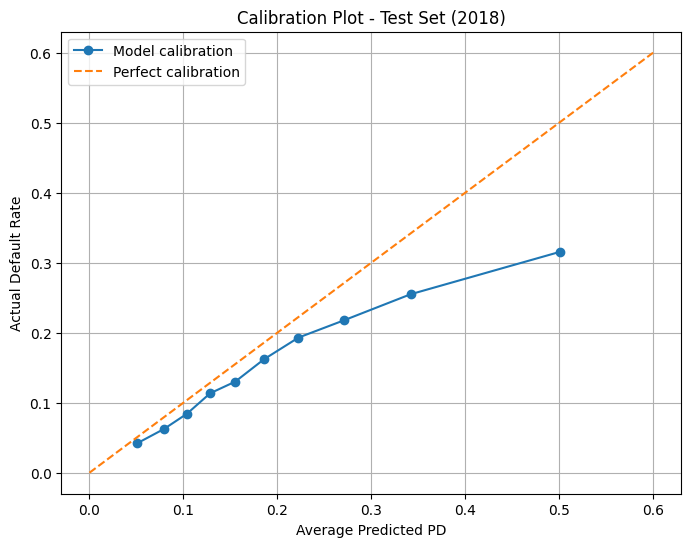

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(
    calibration_table["average_predicted_pd"],
    calibration_table["actual_default_rate"],
    marker="o",
    label="Model calibration"
)

plt.plot(
    [0, 0.6],
    [0, 0.6],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Average Predicted PD")
plt.ylabel("Actual Default Rate")
plt.title("Calibration Plot - Test Set (2018)")

plt.legend()
plt.grid(True)
plt.show()

In [60]:
train_v2 = model_df[
    model_df["issue_date"] < "2016-01-01"
].copy()

calibration_v2 = model_df[
    (model_df["issue_date"] >= "2016-01-01") &
    (model_df["issue_date"] < "2018-01-01")
].copy()

test_v2 = model_df[
    model_df["issue_date"] >= "2018-01-01"
].copy()

In [61]:
print("Train:", train_v2.shape)
print("Calibration:", calibration_v2.shape)
print("Test:", test_v2.shape)

Train: (826606, 153)
Calibration: (462426, 153)
Test: (56318, 153)


In [62]:
print("TRAIN:")
print(train_v2["issue_date"].min())
print(train_v2["issue_date"].max())

print("\nCALIBRATION:")
print(calibration_v2["issue_date"].min())
print(calibration_v2["issue_date"].max())

print("\nTEST:")
print(test_v2["issue_date"].min())
print(test_v2["issue_date"].max())

TRAIN:
2007-06-01 00:00:00
2015-12-01 00:00:00

CALIBRATION:
2016-01-01 00:00:00
2017-12-01 00:00:00

TEST:
2018-01-01 00:00:00
2018-12-01 00:00:00


In [63]:
for dataset in [train_v2, calibration_v2, test_v2]:

    dataset.loc[
        (dataset["dti"] < 0) | (dataset["dti"] > 100),
        "dti"
    ] = np.nan

    dataset.loc[
        dataset["annual_inc"] <= 0,
        "annual_inc"
    ] = np.nan

In [64]:
dti_median = train_v2["dti"].median()
income_median = train_v2["annual_inc"].median()

print("DTI median:", dti_median)
print("Annual income median:", income_median)

DTI median: 17.49
Annual income median: 64000.0


In [65]:
for dataset in [train_v2, calibration_v2, test_v2]:

    dataset["dti"] = dataset["dti"].fillna(dti_median)

    dataset["annual_inc"] = dataset["annual_inc"].fillna(income_median)

In [66]:
print("TRAIN missing values:")
print(train_v2[["dti", "annual_inc"]].isna().sum())

print("\nCALIBRATION missing values:")
print(calibration_v2[["dti", "annual_inc"]].isna().sum())

print("\nTEST missing values:")
print(test_v2[["dti", "annual_inc"]].isna().sum())

TRAIN missing values:
dti           0
annual_inc    0
dtype: int64

CALIBRATION missing values:
dti           0
annual_inc    0
dtype: int64

TEST missing values:
dti           0
annual_inc    0
dtype: int64


In [67]:
features_to_check = [
    "inq_last_6mths",
    "revol_util"
]

print("TRAIN:")
print(train_v2[features_to_check].isna().sum())

print("\nCALIBRATION:")
print(calibration_v2[features_to_check].isna().sum())

print("\nTEST:")
print(test_v2[features_to_check].isna().sum())

TRAIN:
inq_last_6mths      0
revol_util        444
dtype: int64

CALIBRATION:
inq_last_6mths      1
revol_util        339
dtype: int64

TEST:
inq_last_6mths     0
revol_util        74
dtype: int64


In [68]:
revol_util_median = train_v2["revol_util"].median()

print("Revol_util median:", revol_util_median)

Revol_util median: 55.6


In [69]:
for dataset in [train_v2, calibration_v2, test_v2]:

    dataset["revol_util"] = dataset["revol_util"].fillna(revol_util_median)
    dataset["inq_last_6mths"] = dataset["inq_last_6mths"].fillna(train_inq_median)

In [70]:
print("TRAIN missing values:")
print(train_v2[baseline_features].isna().sum().sum())

print("CALIBRATION missing values:")
print(calibration_v2[baseline_features].isna().sum().sum())

print("TEST missing values:")
print(test_v2[baseline_features].isna().sum().sum())

TRAIN missing values:
0
CALIBRATION missing values:
0
TEST missing values:
0


In [71]:
X_train_v2 = train_v2[baseline_features]
X_calibration_v2 = calibration_v2[baseline_features]
X_test_v2 = test_v2[baseline_features]

# y: Target
y_train_v2 = train_v2["default"]
y_calibration_v2 = calibration_v2["default"]
y_test_v2 = test_v2["default"]

In [72]:
print("X_train:", X_train_v2.shape)
print("X_calibration:", X_calibration_v2.shape)
print("X_test:", X_test_v2.shape)

print("y_train:", y_train_v2.shape)
print("y_calibration:", y_calibration_v2.shape)
print("y_test:", y_test_v2.shape)

X_train: (826606, 11)
X_calibration: (462426, 11)
X_test: (56318, 11)
y_train: (826606,)
y_calibration: (462426,)
y_test: (56318,)


In [73]:
from sklearn.preprocessing import StandardScaler

scaler_v2 = StandardScaler()

# Fit only on Train
X_train_v2_scaled = scaler_v2.fit_transform(X_train_v2)

# Transform Calibration and Test
X_calibration_v2_scaled = scaler_v2.transform(X_calibration_v2)
X_test_v2_scaled = scaler_v2.transform(X_test_v2)

In [74]:
print("Train:", X_train_v2_scaled.shape)
print("Calibration:", X_calibration_v2_scaled.shape)
print("Test:", X_test_v2_scaled.shape)

print("\nTrain means:")
print(X_train_v2_scaled.mean(axis=0))

Train: (826606, 11)
Calibration: (462426, 11)
Test: (56318, 11)

Train means:
[-7.26182127e-17  4.40110380e-17 -1.05626491e-16 -1.32033114e-16
  1.83085918e-15 -8.80220760e-18 -3.96099342e-17 -8.36209722e-17
  3.96099342e-17  9.24231798e-17 -1.21030354e-16]


In [75]:
from sklearn.linear_model import LogisticRegression

model_v2 = LogisticRegression(max_iter=1000)

model_v2.fit(X_train_v2_scaled, y_train_v2)

LogisticRegression(max_iter=1000)

In [76]:
raw_calibration_pd = model_v2.predict_proba(
    X_calibration_v2_scaled
)[:, 1]

print(raw_calibration_pd[:10])

[0.21656182 0.39695081 0.18746081 0.1799604  0.16232608 0.11271358
 0.11405581 0.22928135 0.19844315 0.61223521]


In [77]:
actual_calibration_rate = y_calibration_v2.mean()

average_calibration_pd = raw_calibration_pd.mean()

print("Actual default rate:", actual_calibration_rate)
print("Average predicted PD:", average_calibration_pd)

Actual default rate: 0.23229878942793009
Average predicted PD: 0.19831657353531879


In [78]:
from sklearn.metrics import roc_auc_score

auc_calibration_v2 = roc_auc_score(
    y_calibration_v2,
    raw_calibration_pd
)

print("Calibration ROC-AUC:", auc_calibration_v2)

Calibration ROC-AUC: 0.6962090209668341


In [79]:
import numpy as np

eps = 1e-6

cal_pd_clipped = np.clip(
    raw_calibration_pd,
    eps,
    1 - eps
)

cal_logit = np.log(
    cal_pd_clipped / (1 - cal_pd_clipped)
).reshape(-1, 1)

print("Logit shape:", cal_logit.shape)
print("First 10 logits:", cal_logit[:10].flatten())

Logit shape: (462426, 1)
First 10 logits: [-1.28581611 -0.41818642 -1.46659435 -1.51661578 -1.64102175 -2.06331791
 -2.04996611 -1.21237356 -1.39605322  0.45671759]


In [80]:
from sklearn.linear_model import LogisticRegression

platt_model = LogisticRegression()

platt_model.fit(
    cal_logit,
    y_calibration_v2
)

LogisticRegression()

In [81]:
print("Platt coefficient:", platt_model.coef_[0][0])
print("Platt intercept:", platt_model.intercept_[0])

Platt coefficient: 0.8154249723801082
Platt intercept: -0.013113041505255722


In [82]:
raw_test_pd = model_v2.predict_proba(
    X_test_v2_scaled
)[:, 1]

In [83]:
test_pd_clipped = np.clip(
    raw_test_pd,
    eps,
    1 - eps
)

test_logit = np.log(
    test_pd_clipped / (1 - test_pd_clipped)
).reshape(-1, 1)

In [84]:
calibrated_test_pd = platt_model.predict_proba(
    test_logit
)[:, 1]

In [85]:
print("First 10 raw PDs:")
print(raw_test_pd[:10])

print("\nFirst 10 calibrated PDs:")
print(calibrated_test_pd[:10])

First 10 raw PDs:
[0.03821469 0.14859326 0.14737345 0.5145276  0.39092811 0.10780087
 0.05140262 0.04949965 0.25273936 0.0624961 ]

First 10 calibrated PDs:
[0.06640164 0.19207523 0.19085398 0.50857041 0.40740999 0.1497663
 0.08391401 0.08145706 0.28965118 0.097847  ]


In [86]:
actual_test_rate = y_test_v2.mean()

average_raw_test_pd = raw_test_pd.mean()

average_calibrated_test_pd = calibrated_test_pd.mean()

print("Actual Default Rate:", actual_test_rate)
print("Average Raw PD:", average_raw_test_pd)
print("Average Calibrated PD:", average_calibrated_test_pd)

Actual Default Rate: 0.15756951596292482
Average Raw PD: 0.19512189488884338
Average Calibrated PD: 0.22836138399391154


In [87]:
from sklearn.metrics import (
    brier_score_loss,
    roc_auc_score
)

# Brier Score
brier_raw = brier_score_loss(
    y_test_v2,
    raw_test_pd
)

brier_calibrated = brier_score_loss(
    y_test_v2,
    calibrated_test_pd
)

# ROC-AUC
auc_raw = roc_auc_score(
    y_test_v2,
    raw_test_pd
)

auc_calibrated = roc_auc_score(
    y_test_v2,
    calibrated_test_pd
)

print("Raw Brier Score:", brier_raw)
print("Calibrated Brier Score:", brier_calibrated)

print("Raw ROC-AUC:", auc_raw)
print("Calibrated ROC-AUC:", auc_calibrated)

Raw Brier Score: 0.13135552276806842
Calibrated Brier Score: 0.13332370105403796
Raw ROC-AUC: 0.6794530232689117
Calibrated ROC-AUC: 0.6794530232689117


In [88]:
import pandas as pd

raw_calibration_table = pd.DataFrame({
    "actual": y_test_v2.values,
    "predicted_pd": raw_test_pd
})

raw_calibration_table["risk_decile"] = pd.qcut(
    raw_calibration_table["predicted_pd"],
    10,
    labels=False
)

raw_deciles = raw_calibration_table.groupby(
    "risk_decile"
).agg(
    loans=("actual", "count"),
    actual_default_rate=("actual", "mean"),
    average_predicted_pd=("predicted_pd", "mean")
)

print(raw_deciles)

             loans  actual_default_rate  average_predicted_pd
risk_decile                                                  
0             5632             0.039950              0.044173
1             5632             0.062678              0.069098
2             5632             0.087713              0.091376
3             5631             0.111348              0.114653
4             5632             0.135831              0.140587
5             5632             0.163885              0.170717
6             5631             0.187533              0.208441
7             5632             0.220881              0.259624
8             5632             0.254794              0.337682
9             5632             0.311080              0.514856


In [89]:
calibrated_calibration_table = pd.DataFrame({
    "actual": y_test_v2.values,
    "predicted_pd": calibrated_test_pd
})

calibrated_calibration_table["risk_decile"] = pd.qcut(
    calibrated_calibration_table["predicted_pd"],
    10,
    labels=False
)

calibrated_deciles = calibrated_calibration_table.groupby(
    "risk_decile"
).agg(
    loans=("actual", "count"),
    actual_default_rate=("actual", "mean"),
    average_predicted_pd=("predicted_pd", "mean")
)

print(calibrated_deciles)

             loans  actual_default_rate  average_predicted_pd
risk_decile                                                  
0             5632             0.039950              0.074023
1             5632             0.062678              0.105781
2             5632             0.087713              0.131628
3             5631             0.111348              0.157053
4             5632             0.135831              0.183961
5             5632             0.163885              0.213777
6             5631             0.187533              0.249446
7             5632             0.220881              0.295648
8             5632             0.254794              0.362828
9             5632             0.311080              0.509459


In [90]:
ecl_df = pd.DataFrame({
    "default": y_test_v2.values,
    "PD": raw_test_pd,
    "EAD": test_v2["loan_amnt"].values
})

print(ecl_df.head())

print("\nDataset shape:")
print(ecl_df.shape)

print("\nMissing values:")
print(ecl_df.isna().sum())

   default        PD      EAD
0        0  0.038215   3000.0
1        0  0.148593   5000.0
2        0  0.147373   7000.0
3        0  0.514528  30000.0
4        0  0.390928  21000.0

Dataset shape:
(56318, 3)

Missing values:
default    0
PD         0
EAD        0
dtype: int64


In [91]:
lgd_cols = [
    "loan_status",
    "funded_amnt",
    "total_rec_prncp",
    "recoveries",
    "collection_recovery_fee"
]

print(train_v2[lgd_cols].head(10))

   loan_status  funded_amnt  total_rec_prncp  recoveries  \
0   Fully Paid       3600.0           3600.0         0.0   
1   Fully Paid      24700.0          24700.0         0.0   
2   Fully Paid      20000.0          20000.0         0.0   
4   Fully Paid      10400.0          10400.0         0.0   
5   Fully Paid      11950.0          11950.0         0.0   
6   Fully Paid      20000.0          20000.0         0.0   
7   Fully Paid      20000.0          20000.0         0.0   
8   Fully Paid      10000.0          10000.0         0.0   
9   Fully Paid       8000.0           8000.0         0.0   
12  Fully Paid       1400.0           1400.0         0.0   

    collection_recovery_fee  
0                       0.0  
1                       0.0  
2                       0.0  
4                       0.0  
5                       0.0  
6                       0.0  
7                       0.0  
8                       0.0  
9                       0.0  
12                      0.0  


In [92]:
historical_defaults = train_v2[
    train_v2["loan_status"].isin(["Charged Off", "Default"])
].copy()

print(historical_defaults.shape)

print(
    historical_defaults[
        ["loan_status", "funded_amnt", "total_rec_prncp",
         "recoveries", "collection_recovery_fee"]
    ].head(10)
)

(152304, 153)
    loan_status  funded_amnt  total_rec_prncp  recoveries  \
13  Charged Off      18000.0          3481.86     1618.90   
25  Charged Off       4225.0          1536.90      368.37   
30  Charged Off      16000.0         13833.12        0.00   
31  Charged Off      24250.0          1332.69        0.00   
33  Charged Off      25000.0          8364.55        0.00   
41  Charged Off      10000.0          2687.15        0.00   
60  Charged Off      16000.0          2406.29        0.00   
63  Charged Off      35000.0         10323.88     5558.60   
65  Charged Off      14000.0          3175.67     1495.90   
68  Charged Off      20000.0          2965.17     9915.00   

    collection_recovery_fee  
13                 291.4020  
25                  66.3066  
30                   0.0000  
31                   0.0000  
33                   0.0000  
41                   0.0000  
60                   0.0000  
63                1000.5480  
65                 269.2620  
68            

In [93]:
historical_defaults = train_v2[
    train_v2["loan_status"].isin(["Charged Off", "Default"])
].copy()

print(historical_defaults.shape)

print(
    historical_defaults[
        ["loan_status", "funded_amnt", "total_rec_prncp",
         "recoveries", "collection_recovery_fee"]
    ].head(10)
)

(152304, 153)
    loan_status  funded_amnt  total_rec_prncp  recoveries  \
13  Charged Off      18000.0          3481.86     1618.90   
25  Charged Off       4225.0          1536.90      368.37   
30  Charged Off      16000.0         13833.12        0.00   
31  Charged Off      24250.0          1332.69        0.00   
33  Charged Off      25000.0          8364.55        0.00   
41  Charged Off      10000.0          2687.15        0.00   
60  Charged Off      16000.0          2406.29        0.00   
63  Charged Off      35000.0         10323.88     5558.60   
65  Charged Off      14000.0          3175.67     1495.90   
68  Charged Off      20000.0          2965.17     9915.00   

    collection_recovery_fee  
13                 291.4020  
25                  66.3066  
30                   0.0000  
31                   0.0000  
33                   0.0000  
41                   0.0000  
60                   0.0000  
63                1000.5480  
65                 269.2620  
68            

In [94]:
historical_defaults["net_recoveries"] = (
    historical_defaults["recoveries"]
    - historical_defaults["collection_recovery_fee"]
)

historical_defaults["net_loss"] = (
    historical_defaults["funded_amnt"]
    - historical_defaults["total_rec_prncp"]
    - historical_defaults["net_recoveries"]
)

historical_defaults["LGD"] = (
    historical_defaults["net_loss"]
    / historical_defaults["funded_amnt"]
)

print(historical_defaults[
    ["funded_amnt", "total_rec_prncp",
     "net_recoveries", "net_loss", "LGD"]
].head(10))

print("\nLGD statistics:")
print(historical_defaults["LGD"].describe())

    funded_amnt  total_rec_prncp  net_recoveries    net_loss       LGD
13      18000.0          3481.86       1327.4980  13190.6420  0.732813
25       4225.0          1536.90        302.0634   2386.0366  0.564742
30      16000.0         13833.12          0.0000   2166.8800  0.135430
31      24250.0          1332.69          0.0000  22917.3100  0.945044
33      25000.0          8364.55          0.0000  16635.4500  0.665418
41      10000.0          2687.15          0.0000   7312.8500  0.731285
60      16000.0          2406.29          0.0000  13593.7100  0.849607
63      35000.0         10323.88       4558.0520  20118.0680  0.574802
65      14000.0          3175.67       1226.6380   9597.6920  0.685549
68      20000.0          2965.17       8130.3000   8904.5300  0.445227

LGD statistics:
count    152304.000000
mean          0.580917
std           0.222419
min          -0.260522
25%           0.427609
50%           0.614425
75%           0.757570
max           1.000000
Name: LGD, dtype: 

In [95]:
print("Negative LGD:")
print((historical_defaults["LGD"] < 0).sum())

print("\nLGD equal to zero:")
print((historical_defaults["LGD"] == 0).sum())

print("\nLGD equal to 100%:")
print((historical_defaults["LGD"] == 1).sum())

print("\nLGD above 100%:")
print((historical_defaults["LGD"] > 1).sum())

Negative LGD:
69

LGD equal to zero:
8

LGD equal to 100%:
147

LGD above 100%:
0


In [96]:
historical_defaults["LGD_clean"] = (
    historical_defaults["LGD"].clip(0, 1)
)

print("Original mean LGD:")
print(historical_defaults["LGD"].mean())

print("\nClean mean LGD:")
print(historical_defaults["LGD_clean"].mean())

print("\nClean median LGD:")
print(historical_defaults["LGD_clean"].median())

Original mean LGD:
0.5809172948033327

Clean mean LGD:
0.5809419048755663

Clean median LGD:
0.6144250000000535


In [97]:
LGD_value = historical_defaults["LGD_clean"].mean()

ecl_df["LGD"] = LGD_value

ecl_df["ECL"] = (
    ecl_df["PD"]
    * ecl_df["LGD"]
    * ecl_df["EAD"]
)

print(ecl_df.head(10))

   default        PD      EAD       LGD          ECL
0        0  0.038215   3000.0  0.580942    66.601537
1        0  0.148593   5000.0  0.580942   431.620244
2        0  0.147373   7000.0  0.580942   599.307877
3        0  0.514528  30000.0  0.580942  8967.319395
4        0  0.390928  21000.0  0.580942  4769.236941
5        0  0.107801  40000.0  0.580942  2505.041637
6        0  0.051403   5000.0  0.580942   149.309679
7        0  0.049500  15000.0  0.580942   431.346279
8        0  0.252739  12000.0  0.580942  1761.922619
9        0  0.062496   3000.0  0.580942   108.919803


In [98]:
total_ead = ecl_df["EAD"].sum()

total_ecl = ecl_df["ECL"].sum()

average_pd = ecl_df["PD"].mean()

portfolio_ecl_rate = total_ecl / total_ead

print("Total Number of Loans:", len(ecl_df))

print("Total EAD:", round(total_ead, 2))

print("Average PD:", round(average_pd * 100, 2), "%")

print("Total ECL:", round(total_ecl, 2))

print("Portfolio ECL Rate:", round(portfolio_ecl_rate * 100, 2), "%")

Total Number of Loans: 56318
Total EAD: 838076925.0
Average PD: 19.51 %
Total ECL: 104070094.22
Portfolio ECL Rate: 12.42 %


In [99]:
ecl_df["risk_decile"] = pd.qcut(
    ecl_df["PD"],
    q=10,
    labels=False
)

ecl_df["risk_decile"] = ecl_df["risk_decile"] + 1

print(ecl_df["risk_decile"].value_counts().sort_index())

risk_decile
1     5632
2     5632
3     5632
4     5631
5     5632
6     5632
7     5631
8     5632
9     5632
10    5632
Name: count, dtype: int64


In [100]:
risk_summary = ecl_df.groupby("risk_decile").agg(
    number_of_loans=("default", "count"),
    average_pd=("PD", "mean"),
    total_ead=("EAD", "sum"),
    total_ecl=("ECL", "sum"),
    actual_default_rate=("default", "mean")
).reset_index()

risk_summary["ecl_contribution"] = (
    risk_summary["total_ecl"] / total_ecl
)

risk_summary["ecl_contribution"] *= 100

print(risk_summary.round(4))

   risk_decile  number_of_loans  average_pd    total_ead     total_ecl  \
0            1             5632      0.0442   66334425.0  1.685273e+06   
1            2             5632      0.0691   72632525.0  2.920102e+06   
2            3             5632      0.0914   75486850.0  4.010999e+06   
3            4             5631      0.1147   78884150.0  5.255051e+06   
4            5             5632      0.1406   81358775.0  6.645208e+06   
5            6             5632      0.1707   84822500.0  8.420801e+06   
6            7             5631      0.2084   87975300.0  1.065891e+07   
7            8             5632      0.2596   90077550.0  1.358934e+07   
8            9             5632      0.3377   94536400.0  1.855445e+07   
9           10             5632      0.5149  105968450.0  3.232996e+07   

   actual_default_rate  ecl_contribution  
0               0.0400            1.6194  
1               0.0627            2.8059  
2               0.0877            3.8541  
3            

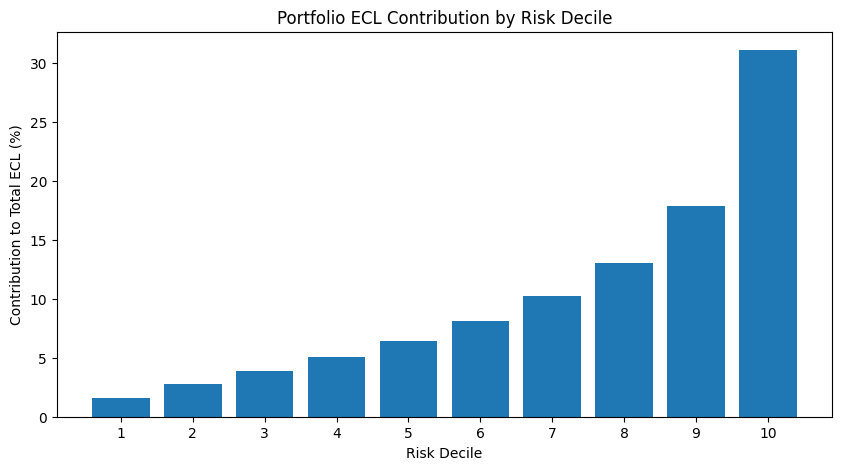

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    risk_summary["risk_decile"],
    risk_summary["ecl_contribution"]
)

plt.xlabel("Risk Decile")
plt.ylabel("Contribution to Total ECL (%)")
plt.title("Portfolio ECL Contribution by Risk Decile")

plt.xticks(range(1, 11))
plt.show()

Model 4 — Credit Strategy SimulationExecutive Overview & Business ObjectiveThe objective of this simulation is to evaluate how changing LendingClub’s underwriting approval threshold affects overall portfolio metrics: total loan approval volume, average portfolio default risk, total Exposure at Default (EAD), and total Expected Credit Loss (ECL).By testing different Probability of Default ($\text{PD}$) cutoff limits, management can find the optimal balance between growth (higher loan originations) and risk control (lower capital provisions and realized default losses).

StrategyApproval Policy ThresholdRisk Profile / ObjectiveConservativeApprove loans with $\text{PD} \le 10\%$Capital Preservation: Strict risk controls. Minimizes credit losses and defaults at the expense of loan volume and market share.BalancedApprove loans with $\text{PD} \le 20\%$Optimal Trade-off: Moderate risk tolerance. Captures standard market demand while filtering out high-risk subprime borrowers.AggressiveApprove loans with $\text{PD} \le 35\%$Growth Focus: Expands credit access to higher-yield/higher-risk segments. Maximizes interest revenue but incurs significantly higher provisioning (ECL).

In [102]:
ecl_df["conservative"] = ecl_df["PD"] <= 0.10

ecl_df["balanced"] = ecl_df["PD"] <= 0.20

ecl_df["aggressive"] = ecl_df["PD"] <= 0.35

print(ecl_df[
    ["PD", "conservative", "balanced", "aggressive"]
].head(10))

         PD  conservative  balanced  aggressive
0  0.038215          True      True        True
1  0.148593         False      True        True
2  0.147373         False      True        True
3  0.514528         False     False       False
4  0.390928         False     False       False
5  0.107801         False      True        True
6  0.051403          True      True        True
7  0.049500          True      True        True
8  0.252739         False     False        True
9  0.062496          True      True        True


In [103]:
strategies = ["conservative", "balanced", "aggressive"]

results = []

for strategy in strategies:

    approved = ecl_df[ecl_df[strategy] == True]

    results.append({
        "strategy": strategy,
        "approved_loans": len(approved),
        "approval_rate": len(approved) / len(ecl_df) * 100,
        "approved_ead": approved["EAD"].sum(),
        "expected_loss": approved["ECL"].sum(),
        "average_pd": approved["PD"].mean() * 100
    })

strategy_results = pd.DataFrame(results)

print(strategy_results.round(2))

       strategy  approved_loans  approval_rate  approved_ead  expected_loss  \
0  conservative           16247          28.85   205525175.0     8090643.22   
1      balanced           35528          63.08   486758350.0    32008896.78   
2    aggressive           48681          86.44   698063500.0    64403185.01   

   average_pd  
0        6.69  
1       10.95  
2       15.09  


In [104]:
strategy_results["ecl_rate"] = (
    strategy_results["expected_loss"]
    / strategy_results["approved_ead"]
) * 100

print(strategy_results[
    ["strategy", "ecl_rate"]
].round(2))

       strategy  ecl_rate
0  conservative      3.94
1      balanced      6.58
2    aggressive      9.23


In [105]:
print(test_v2["term"].value_counts(dropna=False))

term
36 months    41272
60 months    15046
Name: count, dtype: int64


In [106]:
import numpy as np

profit_df = ecl_df.copy()

profit_df["int_rate"] = test_v2["int_rate"].values
profit_df["term"] = test_v2["term"].values

profit_df["term_months"] = (
    profit_df["term"]
    .str.extract(r"(\d+)")
    .astype(int)
)

profit_df["monthly_rate"] = (
    profit_df["int_rate"] / 100 / 12
)

profit_df["monthly_payment"] = (
    profit_df["EAD"]
    * profit_df["monthly_rate"]
    / (
        1 - (1 + profit_df["monthly_rate"])
        ** (-profit_df["term_months"])
    )
)

profit_df["total_interest"] = (
    profit_df["monthly_payment"]
    * profit_df["term_months"]
    - profit_df["EAD"]
)

print(profit_df[
    ["EAD", "int_rate", "term_months",
     "monthly_payment", "total_interest"]
].head(10))

       EAD  int_rate  term_months  monthly_payment  total_interest
0   3000.0      7.34           36        93.098363      351.541067
1   5000.0     11.98           36       166.023791      976.856481
2   7000.0     11.98           36       232.433308     1367.599074
3  30000.0     21.85           36      1143.386919    11161.929097
4  21000.0     20.39           60       560.938398    12656.303883
5  40000.0      9.43           60       838.706775    10322.406488
6   5000.0      5.31           36       150.551393      419.850132
7  15000.0      6.07           36       456.804970     1444.978909
8  12000.0     14.07           36       410.539656     2779.427599
9   3000.0      7.34           36        93.098363      351.541067


In [107]:
profit_df["expected_interest_revenue"] = (
    (1 - profit_df["PD"])
    * profit_df["total_interest"]
)

print(profit_df[
    ["PD", "total_interest", "expected_interest_revenue"]
].head(10))

         PD  total_interest  expected_interest_revenue
0  0.038215      351.541067                 338.107035
1  0.148593      976.856481                 831.702197
2  0.147373     1367.599074                1166.051284
3  0.514528    11161.929097                5418.808460
4  0.390928    12656.303883                7708.598924
5  0.107801    10322.406488                9209.642121
6  0.051403      419.850132                 398.268735
7  0.049500     1444.978909                1373.452964
8  0.252739     2779.427599                2076.956848
9  0.062496      351.541067                 329.571122


In [108]:
strategies = ["conservative", "balanced", "aggressive"]

profit_results = []

for strategy in strategies:

    approved = profit_df[profit_df[strategy] == True]

    expected_revenue = approved[
        "expected_interest_revenue"
    ].sum()

    expected_loss = approved["ECL"].sum()

    net_contribution = expected_revenue - expected_loss

    profit_results.append({
        "strategy": strategy,
        "approved_loans": len(approved),
        "expected_revenue": expected_revenue,
        "expected_loss": expected_loss,
        "net_contribution": net_contribution
    })

profit_results = pd.DataFrame(profit_results)

print(profit_results.round(2))

       strategy  approved_loans  expected_revenue  expected_loss  \
0  conservative           16247      2.746838e+07     8090643.22   
1      balanced           35528      8.569962e+07    32008896.78   
2    aggressive           48681      1.419165e+08    64403185.01   

   net_contribution  
0       19377735.56  
1       53690724.05  
2       77513361.53  


In [109]:
profit_results = profit_results.merge(
    strategy_results[["strategy", "approved_ead"]],
    on="strategy"
)

profit_results["net_contribution_rate"] = (
    profit_results["net_contribution"]
    / profit_results["approved_ead"]
) * 100

print(profit_results[
    ["strategy", "net_contribution_rate"]
].round(2))

       strategy  net_contribution_rate
0  conservative                   9.43
1      balanced                  11.03
2    aggressive                  11.10


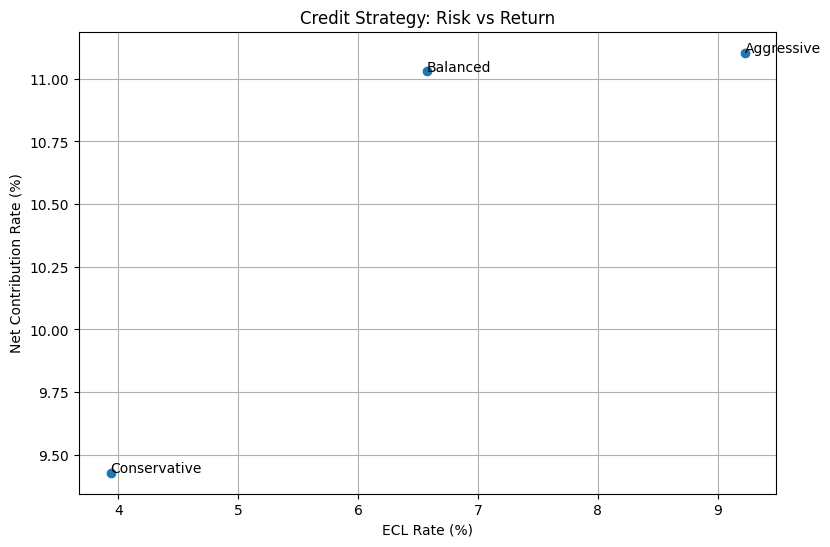

In [110]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    strategy_results["ecl_rate"],
    profit_results["net_contribution_rate"]
)

for i, row in profit_results.iterrows():
    ecl_rate = strategy_results.loc[
        strategy_results["strategy"] == row["strategy"],
        "ecl_rate"
    ].iloc[0]

    plt.annotate(
        row["strategy"].capitalize(),
        (ecl_rate, row["net_contribution_rate"])
    )

plt.xlabel("ECL Rate (%)")
plt.ylabel("Net Contribution Rate (%)")
plt.title("Credit Strategy: Risk vs Return")
plt.grid(True)

plt.show()

In [111]:
final_comparison = profit_results.merge(
    strategy_results[
        ["strategy", "approval_rate", "ecl_rate"]
    ],
    on="strategy"
)

print(final_comparison.round(2))

       strategy  approved_loans  expected_revenue  expected_loss  \
0  conservative           16247      2.746838e+07     8090643.22   
1      balanced           35528      8.569962e+07    32008896.78   
2    aggressive           48681      1.419165e+08    64403185.01   

   net_contribution  approved_ead  net_contribution_rate  approval_rate  \
0       19377735.56   205525175.0                   9.43          28.85   
1       53690724.05   486758350.0                  11.03          63.08   
2       77513361.53   698063500.0                  11.10          86.44   

   ecl_rate  
0      3.94  
1      6.58  
2      9.23  


# Executive Summary
## Credit Risk & Portfolio Profitability Analysis

### 1. Project Objective

The objective of this project is to develop a credit risk
analysis framework using historical LendingClub loan data.

The analysis focuses on:

- Predicting borrower default probability (PD).
- Estimating Expected Credit Loss (ECL).
- Segmenting the loan portfolio by credit risk.
- Simulating alternative credit approval strategies.
- Evaluating the trade-off between portfolio growth
  and credit risk.

### 2. Dataset & Methodology

The analysis uses the LendingClub public loan dataset,
covering loan records from 2007 to 2018.

The dataset contains approximately 2.2 million loan
records and 153 original variables.

For credit risk modelling, the analysis focuses on
loans with terminal outcomes:

- Fully Paid
- Charged Off
- Default

The target variable is defined as:

- 0 = Fully Paid
- 1 = Charged Off or Default

A temporal train-test approach was applied:

- Training period: 2007–2015
- Calibration period: 2016–2017
- Final test period: 2018

The modelling process uses Logistic Regression
to estimate borrower Probability of Default (PD).

Model evaluation includes ROC-AUC and Brier Score.

### 3. Credit Risk Model Performance

A Logistic Regression model was developed to estimate
the Probability of Default (PD).

The model was trained on loans originated between
2007 and 2015 and evaluated on the 2018 test set.

Key model performance results:

- ROC-AUC: 0.6795
- Brier Score: 0.1314
- Actual default rate: 15.76%
- Average predicted PD: 19.51%

The model demonstrates moderate discriminatory
power in distinguishing between default and
non-default borrowers.

However, the predicted probabilities tend to
overestimate the observed default rate in the
2018 test sample.

Platt Scaling was also evaluated using the
2016–2017 calibration period, but it did not
improve the Brier Score on the 2018 test set.
Therefore, the raw Logistic Regression probabilities
were selected for the subsequent ECL analysis.

### 4. Expected Credit Loss (ECL) Analysis

Expected Credit Loss (ECL) was estimated using the
following framework:

ECL = PD × LGD × EAD

Where:

- PD (Probability of Default): Estimated using the
  Logistic Regression model.
- LGD (Loss Given Default): Estimated from historical
  defaulted loans, using a principal-based loss proxy.
- EAD (Exposure at Default): Approximated using the
  original loan amount.

The historical average LGD was estimated at 58.09%.

Key portfolio results for the 2018 test sample:

- Number of loans: 56,318
- Total EAD: approximately €838.08 million
- Average predicted PD: 19.51%
- Total estimated ECL: approximately €104.07 million
- Portfolio ECL rate: 12.42%

The results indicate a significant level of estimated
credit risk within the analysed portfolio.

The ECL calculation represents an educational
approximation and is not a full IFRS 9 implementation.

### 5. Portfolio Risk Segmentation

The loan portfolio was divided into ten risk deciles
based on predicted Probability of Default (PD).

Each decile represents approximately 10% of the
test portfolio, ranked from lowest to highest risk.

The analysis shows a clear increase in actual default
rates across the risk deciles.

Key findings:

- The lowest-risk decile has an actual default rate
  of approximately 4.00%.
- The highest-risk decile has an actual default rate
  of approximately 31.11%.
- The two highest-risk deciles account for
  approximately 48.89% of total estimated ECL.

These findings indicate that estimated credit losses
are concentrated in the highest-risk segments.

Risk segmentation can support targeted credit
policies, portfolio monitoring and risk-based
lending decisions.

### 6. Credit Strategy Simulation

Three alternative credit approval strategies were
simulated to evaluate the trade-off between portfolio
growth and credit risk.

The strategies were defined using predicted PD
thresholds:

- Conservative: Approve loans with PD ≤ 10%.
- Balanced: Approve loans with PD ≤ 20%.
- Aggressive: Approve loans with PD ≤ 35%.

Key results:

| Metric | Conservative | Balanced | Aggressive |
|---|---:|---:|---:|
| Approval Rate | 28.85% | 63.08% | 86.44% |
| Approved Loans | 16,247 | 35,528 | 48,681 |
| Expected Loss | €8.09M | €32.01M | €64.40M |
| ECL Rate | 3.94% | 6.58% | 9.23% |
| Net Contribution | €19.38M | €53.69M | €77.51M |
| Net Contribution Rate | 9.43% | 11.03% | 11.10% |

The Aggressive strategy generates the highest
estimated net contribution, but also carries the
highest credit risk.

The Balanced strategy achieves a similar
net contribution rate with a lower ECL rate.

It may therefore represent a more balanced
approach to portfolio growth and credit risk.

Net contribution is calculated as estimated interest
revenue minus ECL. It does not represent actual
profit, since funding costs and operating expenses
are not included.

### 7. Business Recommendations

Based on the credit risk and portfolio profitability
analysis, the following recommendations are proposed:

1. Adopt the Balanced strategy as the initial
   preferred credit approval policy.

2. Maintain risk-based approval thresholds to
   control portfolio default exposure.

3. Apply enhanced monitoring to high-risk borrowers,
   particularly those in the top two PD deciles.

4. Review credit approval thresholds periodically
   using updated portfolio performance data.

5. Improve expected loss estimation by incorporating
   more accurate outstanding exposure and recovery
   information.

6. Include funding costs and operating expenses
   in future profitability simulations.

The Balanced strategy offers a reasonable compromise
between lending growth and credit risk exposure.

Although the Aggressive strategy generates higher
estimated net contribution, its additional risk
may not justify the relatively small improvement
in contribution rate.



### 8. Limitations and Future Improvements

This project has several methodological limitations:

- The dataset includes only loans with terminal
  outcomes, which may introduce selection bias.
- The 2018 test sample may not represent all loans
  originated during that year.
- The Logistic Regression model has moderate
  predictive performance.
- The EAD is approximated using the original
  loan amount rather than outstanding balance
  at default.
- LGD is based on a simplified historical
  principal-based loss proxy.
- The ECL calculation is not a full IFRS 9 model.
- Profitability estimates exclude funding costs,
  operating expenses and other costs.

Future improvements could include:

- More advanced credit risk models.
- Improved PD calibration.
- More accurate EAD and LGD estimation.
- Funding and operating cost modelling.
- Model monitoring and validation.
- More robust out-of-time testing.

In [112]:
path = kagglehub.dataset_download("wordsforthewise/lending-club")

print(path)

Using Colab cache for faster access to the 'lending-club' dataset.
/kaggle/input/lending-club


In [113]:
for root, dirs, files in os.walk(path):
    for file in files:
        if file == "accepted_2007_to_2018Q4.csv":
            file_path = os.path.join(root, file)

print(file_path)

/kaggle/input/lending-club/accepted_2007_to_2018q4.csv/accepted_2007_to_2018Q4.csv


In [114]:
!pip install duckdb

In [115]:
import duckdb
import kagglehub
import os

In [116]:
con = duckdb.connect("credit_risk.duckdb")

In [117]:
con.execute(f"""
    CREATE OR REPLACE VIEW loans AS
    SELECT
        loan_status,
        grade,
        issue_d,
        annual_inc,
        loan_amnt,
        int_rate,
        term
    FROM read_csv_auto('{file_path}')
""")

In [118]:
con.execute("""
    SELECT *
    FROM loans
    LIMIT 5
""").df()

,loan_status,grade,issue_d,annual_inc,loan_amnt,int_rate,term
0,Fully Paid,C,Dec-2015,55000.0,3600.0,13.99,36 months
1,Fully Paid,C,Dec-2015,65000.0,24700.0,11.99,36 months
2,Fully Paid,B,Dec-2015,63000.0,20000.0,10.78,60 months
3,Current,C,Dec-2015,110000.0,35000.0,14.85,60 months
4,Fully Paid,F,Dec-2015,104433.0,10400.0,22.45,60 months


In [119]:
con.execute("""
    SELECT
        grade,
        COUNT(*) AS total_loans,
        SUM(
            CASE
                WHEN loan_status IN ('Charged Off', 'Default')
                THEN 1
                ELSE 0
            END
        ) AS defaulted_loans,
        ROUND(
            100.0 * SUM(
                CASE
                    WHEN loan_status IN ('Charged Off', 'Default')
                    THEN 1
                    ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS default_rate
    FROM loans
    WHERE loan_status IN ('Fully Paid', 'Charged Off', 'Default')
    GROUP BY grade
    ORDER BY grade
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grade,total_loans,defaulted_loans,default_rate
0,A,235095,14206.0,6.04
1,B,392748,52576.0,13.39
2,C,381694,85657.0,22.44
3,D,200966,61067.0,30.39
4,E,93656,36041.0,38.48
5,F,32059,14492.0,45.20
6,G,9132,4560.0,49.93


The SQL analysis reveals a clear relationship between credit grade and default risk.

Default rates increase consistently from 6.04% for Grade A loans to 49.93% for Grade G loans.

This confirms that lower credit grades are associated with significantly higher default risk.

Credit grade can therefore support risk-based pricing, portfolio segmentation and credit approval decision

In [120]:
con.execute("""
    SELECT
        SUBSTRING(issue_d, 5, 4) AS issue_year,
        COUNT(*) AS total_loans,
        SUM(
            CASE
                WHEN loan_status IN ('Charged Off', 'Default')
                THEN 1
                ELSE 0
            END
        ) AS defaulted_loans,
        ROUND(
            100.0 * SUM(
                CASE
                    WHEN loan_status IN ('Charged Off', 'Default')
                    THEN 1
                    ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS default_rate
    FROM loans
    WHERE loan_status IN ('Fully Paid', 'Charged Off', 'Default')
    GROUP BY issue_year
    ORDER BY issue_year
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,issue_year,total_loans,defaulted_loans,default_rate
0,2007,251,45.0,17.93
1,2008,1562,247.0,15.81
2,2009,4716,594.0,12.60
3,2010,11536,1487.0,12.89
4,2011,21721,3297.0,15.18
5,2012,53367,8644.0,16.20
6,2013,134804,21024.0,15.60
7,2014,223103,41162.0,18.45
8,2015,375546,75804.0,20.19
9,2016,293105,68252.0,23.29


#### SQL Analysis – Default Rate by Year

The SQL analysis shows changes in default rates
across loan origination years.

Default rates increased from approximately
12.60% in 2009 to 23.29% in 2016.

This indicates differences in observed credit
risk across loan vintages.

However, the results should be interpreted
with caution because the dataset includes
only loans with terminal outcomes.

The 2018 default rate may be affected by
loan maturity and selection bias.

In [121]:
con.execute("""
    SELECT
        CASE
            WHEN annual_inc < 30000 THEN 'Low Income'
            WHEN annual_inc < 60000 THEN 'Lower-Middle Income'
            WHEN annual_inc < 100000 THEN 'Upper-Middle Income'
            ELSE 'High Income'
        END AS income_category,

        COUNT(*) AS total_loans,

        SUM(
            CASE
                WHEN loan_status IN ('Charged Off', 'Default')
                THEN 1
                ELSE 0
            END
        ) AS defaulted_loans,

        ROUND(
            100.0 * SUM(
                CASE
                    WHEN loan_status IN ('Charged Off', 'Default')
                    THEN 1
                    ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS default_rate

    FROM loans

    WHERE loan_status IN ('Fully Paid', 'Charged Off', 'Default')
      AND annual_inc > 0
      AND annual_inc IS NOT NULL

    GROUP BY income_category

    ORDER BY
        CASE income_category
            WHEN 'Low Income' THEN 1
            WHEN 'Lower-Middle Income' THEN 2
            WHEN 'Upper-Middle Income' THEN 3
            WHEN 'High Income' THEN 4
        END
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,income_category,total_loans,defaulted_loans,default_rate
0,Low Income,78151,19052.0,24.38
1,Lower-Middle Income,487413,107961.0,22.15
2,Upper-Middle Income,502483,97442.0,19.39
3,High Income,276942,44076.0,15.92


#### SQL Analysis – Default Rate by Income Category

The analysis reveals an inverse relationship
between borrower income and observed default rates.

Borrowers in the Low Income category have a
default rate of 24.38%, compared to 15.92%
for borrowers in the High Income category.

This suggests that borrowers with lower annual
income may face greater difficulties in meeting
their loan repayment obligations.

Annual income can therefore support credit risk
segmentation and lending decisions.

In [122]:
con.execute("""
    SELECT
        grade,
        COUNT(*) AS total_loans,
        SUM(
            CASE
                WHEN loan_status IN ('Charged Off', 'Default')
                THEN loan_amnt
                ELSE 0
            END
        ) AS defaulted_loan_amount,
        ROUND(
            100.0 * SUM(
                CASE
                    WHEN loan_status IN ('Charged Off', 'Default')
                    THEN loan_amnt
                    ELSE 0
                END
            ) / SUM(loan_amnt),
            2
        ) AS defaulted_exposure_rate
    FROM loans
    WHERE loan_status IN ('Fully Paid', 'Charged Off', 'Default')
    GROUP BY grade
    ORDER BY grade
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grade,total_loans,defaulted_loan_amount,defaulted_exposure_rate
0,A,235095,1.951735e+08,5.98
1,B,392748,7.128407e+08,13.71
2,C,381694,1.263444e+09,23.33
3,D,200966,9.776938e+08,31.85
4,E,93656,6.542715e+08,39.65
5,F,32059,2.838272e+08,46.38
6,G,9132,9.345935e+07,49.71


#### SQL Analysis – Defaulted Exposure by Credit Grade

The analysis shows that defaulted loan exposure
increases consistently across lower credit grades.

Grade A has a defaulted exposure rate of 5.98%,
compared to 49.71% for Grade G.

This indicates that lower credit grades are
associated with a greater concentration of
historical defaulted loan exposure.

These findings support risk-based lending,
pricing and portfolio exposure management.

In [123]:
con.execute("""
    SELECT
        grade,
        COUNT(*) AS total_loans,
        ROUND(AVG(int_rate), 2) AS average_interest_rate,
        ROUND(AVG(loan_amnt), 2) AS average_loan_amount
    FROM loans
    WHERE loan_status IN ('Fully Paid', 'Charged Off', 'Default')
    GROUP BY grade
    ORDER BY grade
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grade,total_loans,average_interest_rate,average_loan_amount
0,A,235095,7.11,13892.34
1,B,392748,10.68,13237.62
2,C,381694,14.02,14188.39
3,D,200966,17.72,15272.27
4,E,93656,21.14,17618.25
5,F,32059,24.93,19087.68
6,G,9132,27.73,20588.81


#### SQL Analysis – Interest Rate by Credit Grade

The analysis shows a consistent increase in
average interest rates across lower credit grades.

Average interest rates range from 7.11% for
Grade A loans to 27.73% for Grade G loans.

This indicates that higher-risk borrowers
are charged higher interest rates to compensate
for increased credit risk.

The relationship between credit risk and
interest rates highlights the importance of
considering both expected credit losses and
interest revenue when evaluating lending
strategies.

In [124]:
con.execute("""
    SELECT
        grade,
        COUNT(*) AS total_loans,
        ROUND(AVG(loan_amnt), 2) AS average_loan_amount,
        ROUND(SUM(loan_amnt), 2) AS total_loan_exposure
    FROM loans
    WHERE loan_status IN ('Fully Paid', 'Charged Off', 'Default')
    GROUP BY grade
    ORDER BY grade
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,grade,total_loans,average_loan_amount,total_loan_exposure
0,A,235095,13892.34,3.266021e+09
1,B,392748,13237.62,5.199050e+09
2,C,381694,14188.39,5.415625e+09
3,D,200966,15272.27,3.069207e+09
4,E,93656,17618.25,1.650055e+09
5,F,32059,19087.68,6.119320e+08
6,G,9132,20588.81,1.880170e+08


#### SQL Analysis – Loan Amount by Credit Grade

The analysis shows an increase in average
loan amounts across lower credit grades.

Average loan amounts range from approximately
13,892 for Grade A to 20,589 for Grade G.

However, Grade C represents the largest
total loan exposure, with approximately
5.42 billion in original loan amounts.

This highlights the importance of considering
both individual loan size and portfolio
concentration when assessing credit risk.

In [125]:
con.execute("""
    SELECT
        term,
        COUNT(*) AS total_loans,
        SUM(
            CASE
                WHEN loan_status IN ('Charged Off', 'Default')
                THEN 1
                ELSE 0
            END
        ) AS defaulted_loans,
        ROUND(
            100.0 * SUM(
                CASE
                    WHEN loan_status IN ('Charged Off', 'Default')
                    THEN 1
                    ELSE 0
                END
            ) / COUNT(*),
            2
        ) AS default_rate,
        ROUND(AVG(int_rate), 2) AS average_interest_rate
    FROM loans
    WHERE loan_status IN ('Fully Paid', 'Charged Off', 'Default')
    GROUP BY term
    ORDER BY term
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,term,total_loans,defaulted_loans,default_rate,average_interest_rate
0,36 months,1020768,163277.0,16.00,12.12
1,60 months,324582,105322.0,32.45,16.77


#### SQL Analysis – Default Rate by Loan Term

The analysis shows a significant difference
in observed default rates across loan terms.

Loans with a 36-month term have a default
rate of 16.00%, compared to 32.45% for
loans with a 60-month term.

Longer-term loans also have higher average
interest rates (16.77% versus 12.12%).

These findings suggest that loan maturity
is an important dimension for credit risk
segmentation and risk-based pricing.

However, the relationship does not imply
causation, as borrower characteristics may
also influence default risk.

In [127]:
required_vars = [
    "ecl_df",
    "profit_df",
    "test_v2",
    "strategy_results"
]

for var in required_vars:
    print(var, ":", var in globals())

ecl_df : True
profit_df : True
test_v2 : True
strategy_results : True


In [128]:
print("Columns in test_v2:")
print([col for col in ["grade", "int_rate", "term", "id"] if col in test_v2.columns])

print("\nColumns in profit_df:")
print(profit_df.columns.tolist())

Columns in test_v2:
['grade', 'int_rate', 'term', 'id']

Columns in profit_df:
['default', 'PD', 'EAD', 'LGD', 'ECL', 'risk_decile', 'conservative', 'balanced', 'aggressive', 'int_rate', 'term', 'term_months', 'monthly_rate', 'monthly_payment', 'total_interest', 'expected_interest_revenue']


In [129]:
powerbi_df = profit_df.copy()

powerbi_df["grade"] = test_v2["grade"].values
powerbi_df["loan_id"] = test_v2["id"].astype(str).values

# Έλεγχος αποτελέσματος
print("Dataset shape:", powerbi_df.shape)
print("\nColumns:")
print(powerbi_df.columns.tolist())

print("\nPreview:")
display(powerbi_df.head())

print("\nMissing values:")
print(powerbi_df.isnull().sum())

Dataset shape: (56318, 18)

Columns:
['default', 'PD', 'EAD', 'LGD', 'ECL', 'risk_decile', 'conservative', 'balanced', 'aggressive', 'int_rate', 'term', 'term_months', 'monthly_rate', 'monthly_payment', 'total_interest', 'expected_interest_revenue', 'grade', 'loan_id']

Preview:


,default,PD,EAD,LGD,ECL,risk_decile,conservative,balanced,aggressive,int_rate,term,term_months,monthly_rate,monthly_payment,total_interest,expected_interest_revenue,grade,loan_id
0,0,0.038215,3000.0,0.580942,66.601537,1,True,True,True,7.34,36 months,36,0.006117,93.098363,351.541067,338.107035,A,130956066
1,0,0.148593,5000.0,0.580942,431.620244,5,False,True,True,11.98,36 months,36,0.009983,166.023791,976.856481,831.702197,B,130968727
2,0,0.147373,7000.0,0.580942,599.307877,5,False,True,True,11.98,36 months,36,0.009983,232.433308,1367.599074,1166.051284,B,130910225
3,0,0.514528,30000.0,0.580942,8967.319395,10,False,False,False,21.85,36 months,36,0.018208,1143.386919,11161.929097,5418.808460,D,130966492
4,0,0.390928,21000.0,0.580942,4769.236941,9,False,False,False,20.39,60 months,60,0.016992,560.938398,12656.303883,7708.598924,D,130942737



Missing values:
default                      0
PD                           0
EAD                          0
LGD                          0
ECL                          0
risk_decile                  0
conservative                 0
balanced                     0
aggressive                   0
int_rate                     0
term                         0
term_months                  0
monthly_rate                 0
monthly_payment              0
total_interest               0
expected_interest_revenue    0
grade                        0
loan_id                      0
dtype: int64


In [130]:
powerbi_df.to_csv(
    "/content/powerbi_loan_level.csv",
    index=False
)

print("CSV exported successfully!")

CSV exported successfully!


In [131]:
from google.colab import files

files.download("/content/powerbi_loan_level.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>